In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "03"

# 03 · Is it an ideal current source?

**Question:** hosting-capacity studies model an inverter as an ideal harmonic current source. Does this
inverter behave like one?

An ideal current source has three properties. We test each:

1. The voltage it causes at the PCC is just **grid impedance × its current**, nothing more.
2. It puts **nothing** at frequencies it was not asked for.
3. Its current does **not change** when the grid voltage is already distorted.

## 1. Voltage = grid impedance × current

**Setup.** `sweep.py`, "single" sweep: inject **one order at a time** at its IEEE 1547 limit, all others
at zero, on SCR 10 and SCR 5 (HIL404). Divide the harmonic voltage at the PCC by the harmonic current.
For an ideal source this ratio is exactly the grid impedance at that frequency.

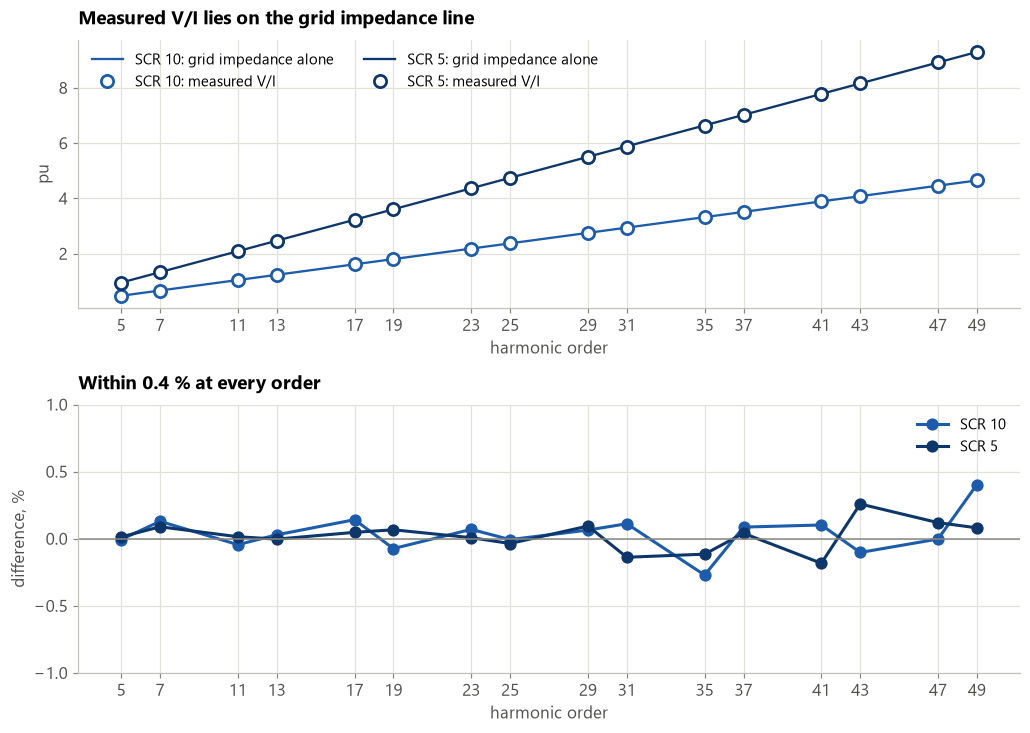

In [2]:
o = A.load("sweep_hil404_orders.csv")
o = o[(o.sweep == "single") & (o.order == o.only)].copy()
o["V_over_I_pu"] = o.V_pct / o.I_pct
o["Zgrid_pu"] = [A.grid_z_pu(g, h) for g, h in zip(o.grid, o.order)]
o["diff_pct"] = (o.V_over_I_pu / o.Zgrid_pu - 1) * 100
fig, ax = A.panels(2, h=3.4)
for g in ("SCR 10", "SCR 5"):
    x = o[o.grid == g]
    ax[0].plot(x.order, x.Zgrid_pu, color=A.GRID_COLOR[g], lw=1.5, label="%s: grid impedance alone" % g)
    ax[0].plot(x.order, x.V_over_I_pu, "o", color=A.GRID_COLOR[g], ms=8, mfc="white", mew=1.8, label="%s: measured V/I" % g)
    ax[1].plot(x.order, x.diff_pct, "o-", color=A.GRID_COLOR[g], label=g)
ax[0].set_ylabel("pu"); A.orders_axis(ax[0]); ax[0].legend(ncol=2, loc="upper left")
ax[0].set_title("Measured V/I lies on the grid impedance line")
ax[1].axhline(0, color=A.MUTED, lw=1); ax[1].set_ylim(-1, 1); A.orders_axis(ax[1])
ax[1].set_ylabel("difference, %"); ax[1].legend()
ax[1].set_title("Within %.1f %% at every order" % o.diff_pct.abs().max())
A.save(fig, "03_impedance", o[["grid", "order", "I_pct", "V_pct", "V_over_I_pu", "Zgrid_pu", "diff_pct"]])
claim("C3.1", "Single order at a time (HIL404, SCR 10 and 5): PCC voltage / current equals the grid impedance within",
      "%.1f %%" % o.diff_pct.abs().max(), "results/sweep_hil404_orders.csv (sweep 'single')")

**Reading.** The circles (measured) sit on the lines (grid impedance only). The inverter adds no
impedance of its own at these orders: the PCC voltage is exactly what an ideal current source would give.

## 2. Nothing where it was not asked

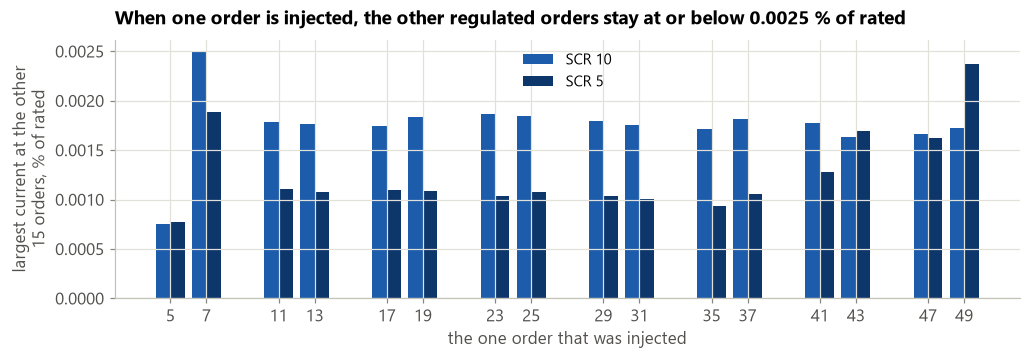

In [3]:
p = A.load("sweep_hil404_points.csv")
q = p[p.sweep == "single"]
fig, ax = A.panels(1, h=3.4)
for i, g in enumerate(("SCR 10", "SCR 5")):
    x = q[q.grid == g]
    ax[0].bar(x.only + (i - 0.5) * 0.8, x.max_unrequested_I_pct_rated, 0.8, color=A.GRID_COLOR[g], label=g)
A.orders_axis(ax[0]); ax[0].set_xlabel("the one order that was injected")
ax[0].set_ylabel("largest current at the other\n15 orders, % of rated")
ax[0].set_title("When one order is injected, the other regulated orders stay at or below %.4f %% of rated" % q.max_unrequested_I_pct_rated.max())
ax[0].legend()
A.save(fig, "03_unrequested", q[["grid", "only", "max_unrequested_I_pct_rated"]])
claim("C3.2", "Current at regulated orders that were not requested (single-order sweep, HIL404)",
      "at most %.4f %% of rated" % q.max_unrequested_I_pct_rated.max(), "results/sweep_hil404_points.csv")

**Reading.** For comparison, the smallest request is 0.3 % of rated. What appears at the other orders is
about 100 times smaller.

### And between the regulated orders?

The controller only regulates 16 orders. Even orders, triplen orders (3rd, 9th, ...) and the switching
band are not controlled. From the 50 kHz waveform captures (HIL404, full request) we look at the whole
spectrum.

**Content outside the regulated orders, % of rated current (root-sum-square, HIL404):**

| grid | even orders 2-50 | triplen orders 3-45 | above 5 kHz |
|---|---|---|---|
| stiff | 0.0997 | 0.000758 | 0.0678 |
| SCR 20 | 0.0662 | 0.00213 | 0.0271 |
| SCR 10 | 0.0548 | 0.129 | 0.0195 |
| SCR 5 (still recovering) | 0.0499 | 1.26 | 0.0181 |

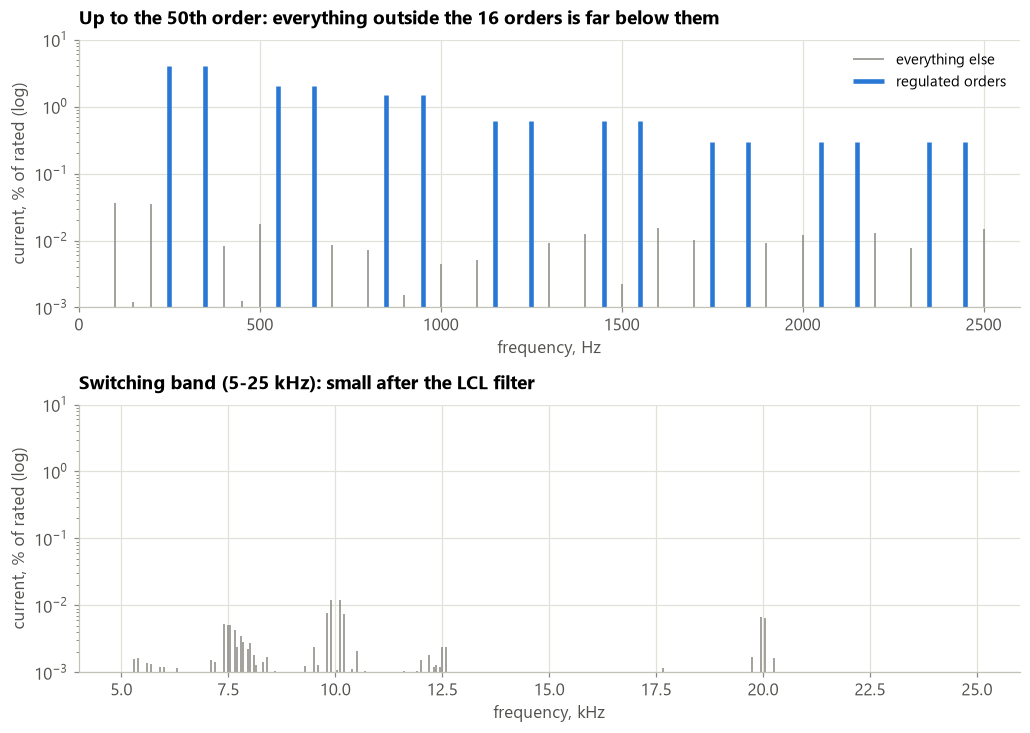

In [4]:
w = A.load("bench_hil404_wave_SCR20.csv")
f, amp = A.spectrum(w, "Ia")
fig, ax = A.panels(2, h=3.4)
reg = np.isin(np.round(f / 50), P.ORDERS) & (np.abs(f / 50 - np.round(f / 50)) < 1e-6)
ax[0].vlines(f[(f > 60) & (f < 2600) & ~reg], 1e-4, amp[(f > 60) & (f < 2600) & ~reg], color=A.MUTED, lw=1, label="everything else")
ax[0].vlines(f[reg], 1e-4, amp[reg], color=A.USED, lw=3, label="regulated orders")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-3, 10); ax[0].set_xlim(0, 2600)
ax[0].set_xlabel("frequency, Hz"); ax[0].set_ylabel("current, % of rated (log)")
ax[0].set_title("Up to the 50th order: everything outside the 16 orders is far below them")
ax[0].legend(loc="upper right")
sw = (f > 5000)
ax[1].vlines(f[sw] / 1e3, 1e-4, amp[sw], color=A.MUTED, lw=1)
ax[1].set_yscale("log"); ax[1].set_ylim(1e-3, 10)
ax[1].set_xlabel("frequency, kHz"); ax[1].set_ylabel("current, % of rated (log)")
ax[1].set_title("Switching band (5-25 kHz): small after the LCL filter")
A.save(fig, "03_spectrum_SCR20", pd.DataFrame({"f_Hz": f, "I_pct_rated": amp}))
rows = []
for g, fn in [("stiff", "stiff"), ("SCR 20", "SCR20"), ("SCR 10", "SCR10"), ("SCR 5 (still recovering)", "SCR5")]:
    ff, aa = A.spectrum(A.load("bench_hil404_wave_%s.csv" % fn), "Ia")
    rows.append({"grid": g, **A.outside_regulated(ff, aa)})
u = pd.DataFrame(rows)
display(Markdown("**Content outside the regulated orders, % of rated current (root-sum-square, HIL404):**\n\n" + A.md_table(u)))
u.to_csv(os.path.join(A.FIG, "03_outside_regulated.csv"), index=False)
claim("C3.3", "Settled grids (stiff, SCR 20, SCR 10): even orders / triplens / above 5 kHz, at most",
      "%.2f / %.2f / %.2f %% of rated" % tuple(u.iloc[:3, 1:].max()), "results/bench_hil404_wave_*.csv")

**Reading.** On the settled grids, everything outside the 16 orders is around 0.1 % of rated or less.
The SCR 5 row is larger at the triplens (about 1.3 %), but that capture was taken while the inverter was
still recovering from the grid step at 750 V DC (notebook 06); it is not a settled result.

Caveat: the capture is sampled at 50 kHz, so anything above 25 kHz folds back into the band shown. The
switching-band numbers are a rough check, not a measurement to a standard. The small group near
7.5 kHz may be such folded-back content.

## 3. Unchanged by background distortion

**Setup.** `sweep.py`, "bg" sweep: the grid voltage itself carries 5th and 7th harmonics at 0, 1, 2 and
3 %, with the full request, on SCR 10 and SCR 5 (HIL404).

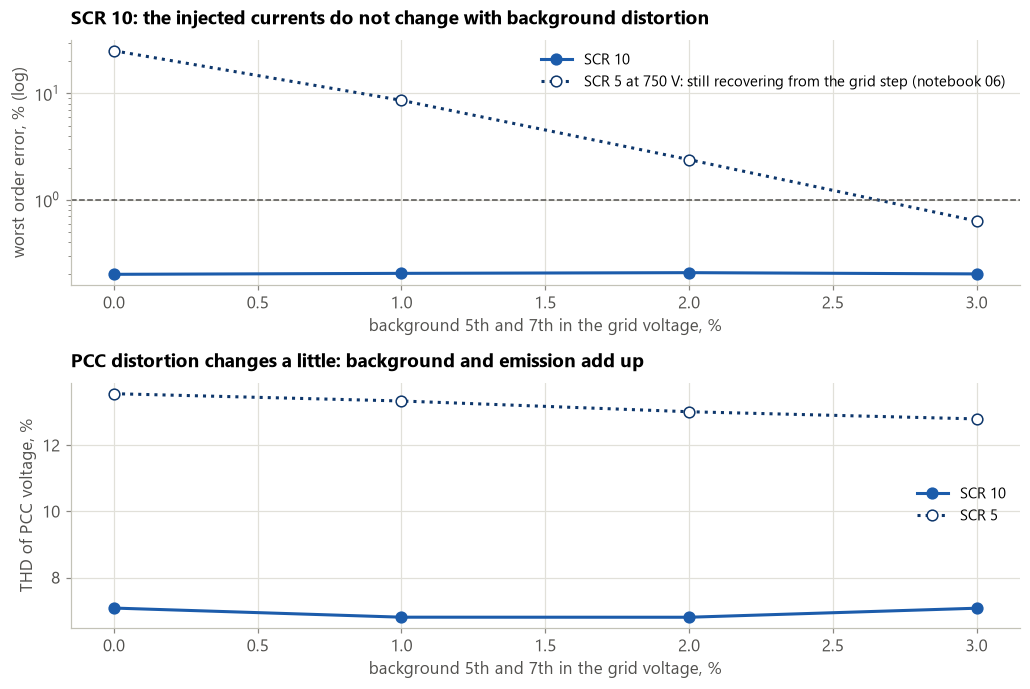

In [5]:
q = p[p.sweep == "bg"]
fig, ax = A.panels(2, h=3.2)
for g in ("SCR 10", "SCR 5"):
    x = q[q.grid == g]
    lab = g if g == "SCR 10" else "SCR 5 at 750 V: still recovering from the grid step (notebook 06)"
    sty = dict(marker="o", ls="-", color=A.GRID_COLOR[g]) if g == "SCR 10" else dict(marker="o", ls=":", mfc="white", color=A.GRID_COLOR[g])
    ax[0].plot(x.bg, x.worst_order_error_pct, label=lab, **sty)
    ax[1].plot(x.bg, x.THD_V_pct, label=g, **sty)
ax[0].set_yscale("log"); ax[0].axhline(1, color=A.LIMIT, ls="--", lw=1)
ax[0].set_ylabel("worst order error, % (log)"); ax[0].set_xlabel("background 5th and 7th in the grid voltage, %")
ax[0].set_title("SCR 10: the injected currents do not change with background distortion")
ax[0].legend(loc="upper right")
ax[1].set_ylabel("THD of PCC voltage, %"); ax[1].set_xlabel("background 5th and 7th in the grid voltage, %")
ax[1].set_title("PCC distortion changes a little: background and emission add up")
ax[1].legend()
A.save(fig, "03_background", q[["grid", "bg", "worst_order_error_pct", "THD_V_pct"]])
claim("C3.4", "Worst order error with 0-3 % background 5th/7th (HIL404, SCR 10)",
      "%.2f-%.2f %%" % (q[q.grid == "SCR 10"].worst_order_error_pct.min(), q[q.grid == "SCR 10"].worst_order_error_pct.max()),
      "results/sweep_hil404_points.csv (sweep 'bg')")

**Reading.** SCR 10 (solid) stays flat at about 0.2 %. The SCR 5 points (dotted) fall from 25 % to
under 1 % **over time**: the four points were taken one after another, just after the grid was stepped to
SCR 5 at 750 V, and the inverter was still recovering (notebook 06). That is not an effect of the
background, so SCR 5 is not used for this claim.

## So: is it an ideal current source?

**At its 16 regulated orders, on an R-L grid, when it is stable, tracking the grid frequency and has
enough DC voltage: yes.** The next three notebooks are those three conditions. Outside the regulated
orders it is not controlled, and with cable capacitance in the network (a real feeder) the filter and
the network can interact at frequencies the controller does not regulate. That case is not in this
repository.

In [6]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C3.1 | Single order at a time (HIL404, SCR 10 and 5): PCC voltage / current equals the grid impedance within | 0.4 % | results/sweep_hil404_orders.csv (sweep 'single') |
| C3.2 | Current at regulated orders that were not requested (single-order sweep, HIL404) | at most 0.0025 % of rated | results/sweep_hil404_points.csv |
| C3.3 | Settled grids (stiff, SCR 20, SCR 10): even orders / triplens / above 5 kHz, at most | 0.10 / 0.13 / 0.07 % of rated | results/bench_hil404_wave_*.csv |
| C3.4 | Worst order error with 0-3 % background 5th/7th (HIL404, SCR 10) | 0.20-0.21 % | results/sweep_hil404_points.csv (sweep 'bg') |